# 08 · Graph Neural Networks

This notebook is a module of **Neural Networks 1002** and assumes [module 02 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) (backpropagation and the layer as a matrix product), [module 03](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) (training well: Adam, weight decay, dropout, early stopping) and [module 09](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) (the transformer, because graph attention is its close cousin).

Images are grids and text is a line. A great deal of real data is neither: a **molecule** is atoms joined by bonds, a **social or citation network** is people or papers joined by links, a **road network** is junctions joined by streets, a **power grid** is substations joined by lines. These objects have no fixed size, no natural order of the nodes, and the information is in *who is connected to whom*. A **graph neural network** (GNN) is a network designed for exactly this.

In this notebook you will build, in pure PyTorch (no graph library), and run on a laptop CPU:

1. the **representation** of a graph (adjacency matrix, edge list, node features) and the reason why a model for graphs must be **permutation invariant**;
2. **message passing** written from scratch (aggregate the neighbours, then update the node) and checked against a plain matrix product;
3. the three classic layers: the **graph convolutional network** (GCN), **GraphSAGE** (sample and aggregate) and the **graph attention network** (GAT), plus the **GIN** (graph isomorphism network) layer, which uses a sum;
4. **node classification** on a generated network with known communities, against a model that ignores the graph (an MLP, multilayer perceptron) and a feature baseline (logistic regression);
5. **over-smoothing** and **over-squashing**, the two failure modes that appear when you stack many layers, measured by depth;
6. **graph-level prediction** with a **readout** (pooling) on a real small-molecule dataset (MUTAG, 188 molecules labelled by mutagenicity), with a 5-fold cross-validation and the same two baselines;
7. a short tour of where GNNs run in production (weather, traffic, drug discovery, power grids, recommendation).

**Contents**

1. Why graphs
2. Representing a graph
3. Message passing from scratch
4. GCN, GraphSAGE, GAT and GIN
5. Node classification: communities in a network
6. Depth: over-smoothing and over-squashing
7. Graph-level tasks: molecules and the readout
8. Where GNNs are used in production
9. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [02 Neural network and backprop (1001)](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) | a layer is a linear map plus a nonlinearity; autograd differentiates all of it |
| [03 Training deep networks (1001)](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) | Adam, weight decay, dropout, picking the epoch with a validation set |
| [09 Transformer (1001)](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) | attention as a softmax-weighted average, which is section 4's GAT |

New to PyTorch? The [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) introduces it. The toy here is small (hundreds of nodes, 188 molecules of about 18 atoms each), and the whole notebook runs in a few minutes on a CPU with fixed random seeds. The only download is MUTAG (24 kB, cached in `data/`).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/08_graph_neural_networks.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: about 1 to 2 minutes, with a peak memory of under 1 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, io, time, math, random, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100
T_START = time.time()

## 1. Why graphs

A convolutional network (module 05 of Neural Networks 1001) exploits one property of images: every pixel has the same kind of neighbourhood, a fixed 3 by 3 or 5 by 5 window, so one small filter can slide everywhere. A recurrent network or a transformer exploits the order of a sequence. A graph has neither a grid nor an order:

* **Irregular structure.** One atom has 1 neighbour, another has 4. One user follows 3 accounts, another 3000. A filter with a fixed number of weights per neighbour cannot be applied to that.
* **No canonical ordering.** If we number the atoms of a molecule 1 to 18 and then renumber them in another order, it is *the same molecule*. A model that gives a different answer after the renumbering has learned something about our bookkeeping, not about chemistry.
* **Variable size.** A molecule of 12 atoms and one of 40 must go through the same network.

The second point is the one that shapes everything. A function $f$ of the node features is **permutation invariant** when it gives the same output for any renumbering of the nodes, and a function that returns one vector per node is **permutation equivariant** when renumbering the input just renumbers the output in the same way. The recipe that satisfies both is to let each node combine the features of its neighbours with a symmetric operation such as a sum, a mean or a maximum. That is **message passing**, the subject of this notebook. Bronstein et al. (2021) show that CNNs, GNNs and transformers are all instances of one idea: respect the symmetry of the data (see the references).

## 2. Representing a graph

A graph $G = (V, E)$ is a set of **nodes** $V$ (here $n = |V|$ of them, $|V|$ meaning "the number of elements of $V$") and a set of **edges** $E$, each a pair of nodes. We work with **undirected** graphs: an edge $i - j$ is stored in both directions, $i \to j$ and $j \to i$. The data attached to it:

| Object | Symbol | Shape | Meaning |
|---|---|---|---|
| node features | $X$ | $n \times d$ | one row $x_i$ per node (for an atom: a one-hot vector of its element) |
| adjacency matrix | $A$ | $n \times n$ | $A_{ij} = 1$ if there is an edge between $i$ and $j$, else $0$ |
| degree | $d_i$ | $n$ | number of neighbours of node $i$, $d_i = \sum_j A_{ij}$ |
| edge list | `edge_index` | $2 \times m$ | row 0 holds the **source** node, row 1 the **destination** node of each of the $m$ directed edges |
| labels | $y$ | $n$ or one per graph | what we want to predict |

The adjacency matrix is easy to reason about but wastes memory: a social network of a million people would need $10^{12}$ cells, almost all zero. The **edge list** stores only the $m$ edges that exist, and it is what real libraries use. We will write everything with the edge list and use the adjacency matrix only to check our work.

Let us build a tiny molecule-like graph (a six-atom ring with a side chain), see both representations, and test the symmetry argument of section 1 numerically: the **sum of node features** does not change if we renumber the nodes, but a function that looks at the *position* of nodes does.

In [2]:
# A toy molecule: a ring of 6 atoms (0..5) with a 2-atom chain (6, 7) attached to atom 0.
bonds = [(0,1),(1,2),(2,3),(3,4),(4,5),(5,0),(0,6),(6,7)]
n = 8
src = [a for a, b in bonds] + [b for a, b in bonds]      # both directions
dst = [b for a, b in bonds] + [a for a, b in bonds]
edge_index = torch.tensor([src, dst])                    # shape 2 x m, m = 16 directed edges
A = torch.zeros(n, n); A[edge_index[0], edge_index[1]] = 1
elements = ["C","C","C","C","C","C","N","O"]
X = torch.tensor([[e == s for s in ["C","N","O"]] for e in elements], dtype=torch.float32)
print("edge_index:\n", edge_index)
print("degrees:", A.sum(1).int().tolist())
print("symmetric adjacency:", bool((A == A.T).all()))

# renumber the nodes with a random permutation P: features X -> X[perm], adjacency A -> A[perm][:, perm]
perm = torch.randperm(n)
X_p, A_p = X[perm], A[perm][:, perm]
print("sum of node features, original :", X.sum(0).tolist())
print("sum of node features, renumbered:", X_p.sum(0).tolist(), "(identical: permutation invariant)")
print("features of the row at position 6 (the nitrogen atom), original vs renumbered:", X[6].tolist(), X_p[6].tolist(), "(position-based reads differ: not invariant)")

edge_index:
 tensor([[0, 1, 2, 3, 4, 5, 0, 6, 1, 2, 3, 4, 5, 0, 6, 7],
        [1, 2, 3, 4, 5, 0, 6, 7, 0, 1, 2, 3, 4, 5, 0, 6]])
degrees: [3, 2, 2, 2, 2, 2, 2, 1]
symmetric adjacency: True
sum of node features, original : [6.0, 1.0, 1.0]
sum of node features, renumbered: [6.0, 1.0, 1.0] (identical: permutation invariant)
features of the row at position 6 (the nitrogen atom), original vs renumbered: [0.0, 1.0, 0.0] [1.0, 0.0, 0.0] (position-based reads differ: not invariant)


## 3. Message passing from scratch

Gilmer et al. (2017) showed that most graph networks fit one template. Every layer does, for every node $i$ at the same time:

1. **Message.** Each neighbour $j$ sends a vector computed from its current features: $m_{j \to i} = \phi(h_j)$, where $h_j$ is the current **hidden vector** (embedding) of node $j$ and $\phi$ is a learned function, here a linear map $W h_j$.
2. **Aggregate.** Node $i$ combines the incoming messages with a symmetric operation: $a_i = \bigoplus_{j \in \mathcal{N}(i)} m_{j \to i}$, where $\mathcal{N}(i)$ is the set of neighbours of $i$ and $\bigoplus$ is a sum, a mean or a maximum. Because the operation does not depend on the order, the layer is permutation equivariant.
3. **Update.** The node mixes the aggregate with its own state: $h_i' = \sigma(\psi(h_i, a_i))$, where $\psi$ is a learned function and $\sigma$ a nonlinearity such as ReLU.

After $k$ layers the vector of node $i$ depends on all nodes within $k$ hops, its **receptive field**, the graph analogue of the receptive field of a CNN. Below, the first version is a slow Python loop that mirrors the description word for word, the second is the vectorised version that the rest of the notebook uses (`index_add_` adds each message into the row of its destination node), and we check them against the matrix product $A\,H$, which for a sum aggregation is exactly "for every node, add up the features of its neighbours".

In [3]:
def aggregate(msgs, dst, n, kind="sum"):
    # Combine the message of every edge into the row of its destination node.
    out = torch.zeros(n, msgs.shape[1])
    if kind in ("sum", "mean"):
        out = out.index_add(0, dst, msgs)
        if kind == "mean":
            deg = torch.zeros(n).index_add(0, dst, torch.ones(len(dst))).clamp(min=1)
            out = out / deg[:, None]
    elif kind == "max":
        out = out.scatter_reduce(0, dst[:, None].expand_as(msgs), msgs, "amax", include_self=False)
    return out

def mp_loop(H, edge_index):
    # the textbook version: for every node, loop over its neighbours and add their messages
    n = H.shape[0]
    out = torch.zeros_like(H)
    for i in range(n):
        for s, d in edge_index.T.tolist():
            if d == i:
                out[i] += H[s]            # message = the neighbour's features, aggregate = sum
    return out

H = torch.randn(n, 4)
a_loop = mp_loop(H, edge_index)
a_vec = aggregate(H[edge_index[0]], edge_index[1], n, "sum")
a_mat = A @ H
print("loop == vectorised:", torch.allclose(a_loop, a_vec, atol=1e-6), "| vectorised == A @ H:", torch.allclose(a_vec, a_mat, atol=1e-6))

# time both on a larger random graph to see why we vectorise
big_n, big_m = 2000, 20000
ei_big = torch.randint(0, big_n, (2, big_m)); H_big = torch.randn(big_n, 16)
t0 = time.time(); [aggregate(H_big[ei_big[0]], ei_big[1], big_n) for _ in range(5)]; t_vec5 = (time.time() - t0) / 5
print(f"vectorised aggregation on {big_n} nodes / {big_m} edges: {t_vec5*1000:.2f} ms (a Python loop over nodes and edges would take minutes)")

# permutation equivariance of the aggregation: renumbering the input renumbers the output
inv = torch.argsort(perm)                      # new index of old node i is inv[i]
ei_perm = inv[edge_index]
agg_perm = aggregate(H[perm][ei_perm[0]], ei_perm[1], n)
print("equivariant (aggregate of renumbered graph == renumbered aggregate):", torch.allclose(agg_perm, a_vec[perm], atol=1e-6))

loop == vectorised: True | vectorised == A @ H: True
vectorised aggregation on 2000 nodes / 20000 edges: 3.83 ms (a Python loop over nodes and edges would take minutes)
equivariant (aggregate of renumbered graph == renumbered aggregate): True


**Reading.** The loop, the vectorised version and the matrix product agree to rounding error, so "message passing with a sum" is nothing mysterious: it is $A H$. The vectorised version costs milliseconds to a few tens of milliseconds for 2000 nodes and 20000 edges, and it scales with the number of edges, not with $n^2$. The last line checks the symmetry claim of section 1: renumbering the nodes of the input renumbers the output rows and changes nothing else.

Everything that makes GCN, GraphSAGE, GAT and GIN different is a choice of *what the message is* and *how neighbours are weighted*.

## 4. GCN, GraphSAGE, GAT and GIN

We implement four layers with the same interface `layer(h, edge_index) -> new h`, each in a few lines, and we use $\ell$ for a layer index. Let $W$ be a learned weight matrix (every layer has its own).

**GCN** (Kipf and Welling, 2017). Add a self-loop to every node, so that a node also listens to itself, and average the neighbours with weights that depend on both degrees:

$$h_i' = \sigma\Big(\sum_{j \in \mathcal{N}(i)\cup\{i\}} \frac{1}{\sqrt{d_i d_j}}\, W h_j\Big), \qquad \text{in matrix form } H' = \sigma(\hat A H W),\quad \hat A = D^{-1/2}(A+I)D^{-1/2},$$

where $D$ is the diagonal matrix of degrees (with the self-loop counted). The factor $1/\sqrt{d_i d_j}$ stops high-degree nodes from dominating. It is a *fixed* weighting, decided by the graph alone.

**GraphSAGE** (Hamilton et al., 2017). Keep the node's own vector and the aggregate of its neighbours separate, with their own weights: $h_i' = \sigma(W_1 h_i + W_2\, \mathrm{mean}_{j \in \mathcal{N}(i)} h_j)$. Separating "me" from "my neighbours" matters when a node is unlike its neighbours. (The original paper also *samples* a fixed number of neighbours per node so that huge graphs fit in memory; we use all neighbours because ours are small.)

**GAT** (Velickovic et al., 2018). Let the network *learn* the weight of each neighbour. For the edge $j \to i$ compute a score $e_{ij} = \mathrm{LeakyReLU}(a_{\text{src}}^\top W h_j + a_{\text{dst}}^\top W h_i)$ (with $a_{\text{src}}, a_{\text{dst}}$ learned vectors), normalise it over the neighbours of $i$ with a softmax, $\alpha_{ij} = \mathrm{softmax}_j(e_{ij})$, and take the weighted sum $h_i' = \sigma(\sum_j \alpha_{ij} W h_j)$. We use several **heads** (independent copies whose outputs are concatenated), as in the transformer.

**GIN** (Xu et al., 2019). A sum with a small MLP: $h_i' = \mathrm{MLP}\big((1+\varepsilon)\,h_i + \sum_{j \in \mathcal{N}(i)} h_j\big)$, with $\varepsilon$ a learned scalar. Sums, unlike means and maxima, can tell apart a node with two identical neighbours from one with a single neighbour, which makes GIN as discriminative as the Weisfeiler-Leman graph test (a classical algorithm for telling graphs apart), the theoretical upper limit for this family.

**Connection to the transformer.** In module 09 of Neural Networks 1001, attention gives every token a softmax-weighted average of the values of *all* other tokens. GAT is the same computation restricted to the neighbours: a transformer is a GAT on the complete graph in which every token is connected to every other one (and where the score is a scaled dot product instead of the additive score above). We verify that statement in the code: a dense attention with an adjacency mask gives exactly the result of the edge-list softmax.

In [4]:
def add_self_loops(ei, n):
    loops = torch.arange(n)
    return torch.stack([torch.cat([ei[0], loops]), torch.cat([ei[1], loops])])

class GCNLayer(nn.Module):
    def __init__(self, din, dout):
        super().__init__(); self.lin = nn.Linear(din, dout, bias=False); self.bias = nn.Parameter(torch.zeros(dout))
    def forward(self, h, ei):
        n = h.shape[0]
        ei = add_self_loops(ei, n)
        deg = torch.zeros(n).index_add(0, ei[1], torch.ones(ei.shape[1]))
        w = (deg[ei[0]] * deg[ei[1]]).rsqrt()                      # 1 / sqrt(d_i d_j) per edge
        return aggregate(self.lin(h)[ei[0]] * w[:, None], ei[1], n, "sum") + self.bias

class SAGELayer(nn.Module):
    def __init__(self, din, dout):
        super().__init__(); self.self_lin = nn.Linear(din, dout); self.nb_lin = nn.Linear(din, dout, bias=False)
    def forward(self, h, ei):
        nb = aggregate(h[ei[0]], ei[1], h.shape[0], "mean")
        return self.self_lin(h) + self.nb_lin(nb)

class GATLayer(nn.Module):
    def __init__(self, din, dout, heads=4):
        super().__init__()
        assert dout % heads == 0
        self.heads, self.dh = heads, dout // heads
        self.lin = nn.Linear(din, dout, bias=False)
        self.a_src = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
        self.a_dst = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
        self.bias = nn.Parameter(torch.zeros(dout))
        self.last_alpha = None
    def forward(self, h, ei):
        n = h.shape[0]
        ei = add_self_loops(ei, n)
        z = self.lin(h).view(n, self.heads, self.dh)
        e = F.leaky_relu((z * self.a_src).sum(-1)[ei[0]] + (z * self.a_dst).sum(-1)[ei[1]], 0.2)   # (m, heads)
        mx = torch.full((n, self.heads), -1e9).scatter_reduce(0, ei[1][:, None].expand_as(e), e, "amax", include_self=True)
        ex = (e - mx[ei[1]]).exp()                                                                   # softmax over the incoming edges of each node
        den = torch.zeros(n, self.heads).index_add(0, ei[1], ex)
        alpha = ex / den[ei[1]]
        self.last_alpha = alpha.detach()
        out = torch.zeros(n, self.heads, self.dh).index_add(0, ei[1], alpha[:, :, None] * z[ei[0]])
        return out.reshape(n, -1) + self.bias

class GINLayer(nn.Module):
    def __init__(self, din, dout):
        super().__init__()
        self.eps = nn.Parameter(torch.zeros(1))
        self.mlp = nn.Sequential(nn.Linear(din, dout), nn.ReLU(), nn.Linear(dout, dout))
    def forward(self, h, ei):
        return self.mlp((1 + self.eps) * h + aggregate(h[ei[0]], ei[1], h.shape[0], "sum"))

class NoGraphLayer(nn.Module):
    # same interface but ignores the edges: stacking these gives an ordinary MLP applied to each node
    def __init__(self, din, dout):
        super().__init__(); self.lin = nn.Linear(din, dout)
    def forward(self, h, ei):
        return self.lin(h)

# check 1: our GCN layer equals the matrix formula  A_hat H W
torch.manual_seed(0)
gcn = GCNLayer(3, 5)
A_hat = A + torch.eye(n); dinv = A_hat.sum(1).rsqrt(); A_hat = dinv[:, None] * A_hat * dinv[None, :]
print("GCN layer == A_hat H W + b:", torch.allclose(gcn(X, edge_index), A_hat @ X @ gcn.lin.weight.T + gcn.bias, atol=1e-5))

# check 2: the GAT edge-list softmax equals a dense masked softmax attention (what a transformer does on the complete graph)
gat = GATLayer(3, 8, heads=1)
out_edges = gat(X, edge_index)
z = gat.lin(X)
e_dense = F.leaky_relu((z * gat.a_src[0]).sum(-1)[None, :] + (z * gat.a_dst[0]).sum(-1)[:, None], 0.2)   # e[i, j]: score of source j for destination i
mask = (A + torch.eye(n)) > 0                                                                             # who may attend to whom
alpha_dense = torch.softmax(e_dense.masked_fill(~mask, float("-inf")), dim=1)
print("GAT == dense attention with an adjacency mask:", torch.allclose(out_edges, alpha_dense @ z + gat.bias, atol=1e-5))
print("attention weights of every node sum to 1:", torch.allclose(alpha_dense.sum(1), torch.ones(n)))
print("with an all-True mask (complete graph) the same code is a transformer's attention over all tokens")

GCN layer == A_hat H W + b: True
GAT == dense attention with an adjacency mask: True
attention weights of every node sum to 1: True
with an all-True mask (complete graph) the same code is a transformer's attention over all tokens


**Reading.** Both layers match their closed forms to rounding error, so the code is a faithful implementation of the equations. The second check is the point of the GAT: replace the adjacency mask by an all-ones mask and the same formula is the attention of module 09. A GNN is therefore a transformer that is only allowed to look along the edges of a given graph, and a transformer is a GNN that has been given the complete graph because the data (a sentence) did not come with one.

Now we need a model class that stacks layers, and optionally pools the nodes of each graph into one vector (the **readout** of section 7), plus two training loops. The "MLP that ignores the graph" is the same class built from `NoGraphLayer`, so the *only* difference between the baseline and a GNN is whether the edges are used.

In [5]:
def pool(h, batch, ngraphs, kind):
    # readout: collapse the nodes of every graph into one vector with a symmetric function
    if kind == "sum":
        return torch.zeros(ngraphs, h.shape[1]).index_add(0, batch, h)
    if kind == "mean":
        cnt = torch.zeros(ngraphs).index_add(0, batch, torch.ones(len(batch))).clamp(min=1)
        return torch.zeros(ngraphs, h.shape[1]).index_add(0, batch, h) / cnt[:, None]
    return torch.zeros(ngraphs, h.shape[1]).scatter_reduce(0, batch[:, None].expand_as(h), h, "amax", include_self=False)

class GNN(nn.Module):
    def __init__(self, layer, din, hid, dout, L=2, readout=None, dropout=0.5, residual=False):
        super().__init__()
        self.layers = nn.ModuleList([layer(din if i == 0 else hid, hid) for i in range(L)])
        self.readout, self.dropout, self.residual = readout, dropout, residual
        self.head = nn.Linear(hid, dout) if readout is None else nn.Sequential(nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, dout))
    def embed(self, x, ei):
        h = x
        for i, layer in enumerate(self.layers):
            h_new = F.relu(layer(F.dropout(h, self.dropout, self.training), ei))
            h = h + h_new if (self.residual and i > 0) else h_new
        return h
    def forward(self, x, ei, batch=None, ngraphs=None):
        h = self.embed(x, ei)
        if self.readout is not None:
            h = pool(h, batch, ngraphs, self.readout)
        return self.head(F.dropout(h, self.dropout, self.training))

def count_params(m):
    return sum(p.numel() for p in m.parameters())

for name, L in [("GCN", GCNLayer), ("GraphSAGE", SAGELayer), ("GAT (4 heads)", GATLayer), ("GIN", GINLayer), ("MLP (no graph)", NoGraphLayer)]:
    print(f"{name:16s} 2 layers, 16 -> 32 -> 4: {count_params(GNN(L, 16, 32, 4)):6d} parameters")

GCN              2 layers, 16 -> 32 -> 4:   1732 parameters
GraphSAGE        2 layers, 16 -> 32 -> 4:   3268 parameters
GAT (4 heads)    2 layers, 16 -> 32 -> 4:   1860 parameters
GIN              2 layers, 16 -> 32 -> 4:   3846 parameters
MLP (no graph)   2 layers, 16 -> 32 -> 4:   1732 parameters


## 5. Node classification: communities in a network

**Task.** Every node of one big graph has a class and we know the class of only a few nodes. Predict the others. This **semi-supervised node classification** is the setting of Kipf and Welling (2017) on citation networks, where a paper's topic is predicted from the words it contains *and* the papers it cites. Real examples: which accounts belong to the same community, which papers share a topic, which transactions look like the known fraudulent ones.

**Data.** We generate the graph, so we know the truth. A **stochastic block model** (SBM) has $K = 4$ communities of 100 nodes. Two nodes of the same community are linked with probability $p_{\text{in}} = 0.06$ and two nodes of different communities with probability $p_{\text{out}} = 0.01$, which gives about 6 in-community and 3 cross-community neighbours per node, so the graph is informative but far from clean. Each node also has a 16-dimensional feature vector: its community's random centre, scaled by 0.4, plus unit Gaussian noise, so features alone are a *weak* signal. Only 10 nodes per community are labelled for training, 100 nodes are used to pick the best epoch (validation) and the other 260 form the test set. We repeat everything on 5 freshly generated graphs. (Zachary's karate club, the classic 34-node example, is too small for a train/test split that means anything; the SBM is the same kind of object at a useful size.)

**Models**, all with the same hidden size of 32 and 2 layers, so they differ only in how neighbours are used: logistic regression on the node features (**feature baseline**), an MLP on the node features (**ignores the graph**), GCN, GraphSAGE, GAT.

SBM graph: 400 nodes, 1769 undirected edges, mean degree 8.8
fraction of edges that join two nodes of the same community (edge homophily): 0.66


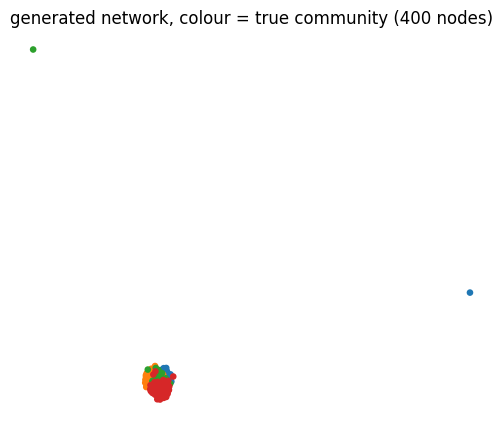

In [6]:
def make_sbm(seed, k=4, size=100, p_in=0.06, p_out=0.01, dim=16, signal=0.4):
    g = np.random.RandomState(seed)
    n = k * size
    y = np.repeat(np.arange(k), size)
    P = np.where(y[:, None] == y[None, :], p_in, p_out)
    upper = np.triu(g.rand(n, n) < P, 1)
    adj = upper | upper.T
    src, dst = np.nonzero(adj)
    centres = g.randn(k, dim)
    x = signal * centres[y] + g.randn(n, dim)
    # split: 10 labelled nodes per community for training, 100 for validation, the rest for test
    train, val, test = [], [], []
    for c in range(k):
        idx = g.permutation(np.where(y == c)[0])
        train += list(idx[:10]); val += list(idx[10:35]); test += list(idx[35:])
    t = lambda a: torch.tensor(np.array(a))
    return dict(x=torch.tensor(x, dtype=torch.float32), ei=torch.tensor(np.stack([src, dst])), y=t(y), train=t(train), val=t(val), test=t(test), adj=adj, n=n)

def layout(ei, n, seed=0, iters=150):
    # a tiny force-directed layout (Fruchterman-Reingold) so that we need no plotting library for graphs
    g = np.random.RandomState(seed); pos = g.rand(n, 2)
    s, d = ei.numpy() if hasattr(ei, "numpy") else ei
    k = 1.0 / math.sqrt(n)
    for it in range(iters):
        diff = pos[:, None, :] - pos[None, :, :]; dist = np.linalg.norm(diff, axis=-1) + 1e-6
        disp = (diff / dist[..., None] * (k * k / dist)[..., None]).sum(1)
        dd = pos[s] - pos[d]; dl = np.linalg.norm(dd, axis=1) + 1e-6
        att = dd / dl[:, None] * (dl ** 2 / k)[:, None]
        np.add.at(disp, s, -att)
        ln = np.linalg.norm(disp, axis=1)[:, None] + 1e-6
        pos += disp / ln * np.minimum(ln, 0.1 * (1 - it / iters) + 0.005)
    return pos

D = make_sbm(0)
cls_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
print(f"SBM graph: {D['n']} nodes, {D['ei'].shape[1] // 2} undirected edges, mean degree {D['ei'].shape[1] / D['n']:.1f}")
same = (D["y"][D["ei"][0]] == D["y"][D["ei"][1]]).float().mean().item()
print(f"fraction of edges that join two nodes of the same community (edge homophily): {same:.2f}")

pos = layout(D["ei"], D["n"])
fig, ax = plt.subplots(figsize=(6.2, 5))
s, d = D["ei"].numpy()
for a, b in zip(s[::2], d[::2]):
    ax.plot(pos[[a, b], 0], pos[[a, b], 1], color="0.8", lw=0.3, zorder=1)
ax.scatter(pos[:, 0], pos[:, 1], c=[cls_colors[c] for c in D["y"].numpy()], s=14, zorder=2)
ax.set_title("generated network, colour = true community (400 nodes)"); ax.axis("off")
plt.show()

5 graphs x 5 models trained in 52 s

model                            test accuracy (mean +- std over 5 graphs)
Logistic regression (features)   0.572 +- 0.079   [0.44, 0.58, 0.59, 0.68, 0.57]
MLP (ignores graph)              0.585 +- 0.064   [0.47, 0.58, 0.6, 0.65, 0.63]
GCN                              0.926 +- 0.019   [0.95, 0.93, 0.89, 0.93, 0.93]
GraphSAGE                        0.878 +- 0.029   [0.85, 0.9, 0.85, 0.92, 0.88]
GAT                              0.922 +- 0.022   [0.95, 0.93, 0.88, 0.91, 0.93]


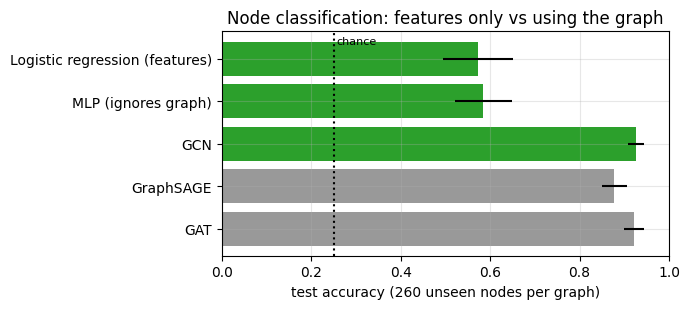

In [7]:
def train_node(model, D, epochs=120, lr=0.01, wd=5e-4):
    # full-batch training; the epoch with the best validation accuracy decides which test accuracy we report
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    best_val, best_test = -1, 0
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        out = model(D["x"], D["ei"])
        F.cross_entropy(out[D["train"]], D["y"][D["train"]]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            pred = model(D["x"], D["ei"]).argmax(1)
        va = (pred[D["val"]] == D["y"][D["val"]]).float().mean().item()
        if va > best_val:
            best_val, best_test = va, (pred[D["test"]] == D["y"][D["test"]]).float().mean().item()
    return best_test

def logreg_acc(D):
    clf = LogisticRegression(max_iter=2000, C=0.5).fit(D["x"][D["train"]].numpy(), D["y"][D["train"]].numpy())
    return clf.score(D["x"][D["test"]].numpy(), D["y"][D["test"]].numpy())

layers = {"MLP (ignores graph)": NoGraphLayer, "GCN": GCNLayer, "GraphSAGE": SAGELayer, "GAT": GATLayer}
node_res = {"Logistic regression (features)": []}
node_res.update({k: [] for k in layers})
t0 = time.time()
for seed in range(5):
    D = make_sbm(100 + seed)
    node_res["Logistic regression (features)"].append(logreg_acc(D))
    for name, L in layers.items():
        torch.manual_seed(seed)
        node_res[name].append(train_node(GNN(L, 16, 32, 4, L=2), D))
print(f"5 graphs x 5 models trained in {time.time() - t0:.0f} s\n")
print(f"{'model':32s} test accuracy (mean +- std over 5 graphs)")
for k, v in node_res.items():
    print(f"{k:32s} {np.mean(v):.3f} +- {np.std(v):.3f}   {np.round(v, 2).tolist()}")

fig, ax = plt.subplots(figsize=(7, 3.2))
names = list(node_res); means = [np.mean(v) for v in node_res.values()]; stds = [np.std(v) for v in node_res.values()]
ax.barh(names[::-1], means[::-1], xerr=stds[::-1], color=["tab:green", "tab:green", "tab:green", "0.6", "0.6"][::-1])
ax.axvline(0.25, color="k", ls=":"); ax.text(0.255, 4.35, "chance", fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel("test accuracy (260 unseen nodes per graph)"); ax.set_title("Node classification: features only vs using the graph")
plt.tight_layout(); plt.show()

**Reading.** With 10 labelled nodes per community, the models that see only the features are barely better than a coin flip among 4 classes: logistic regression 0.57 and the MLP 0.59 (chance is 0.25). Once the same features are allowed to flow along the edges, accuracy jumps to 0.93 for the GCN, 0.92 for the GAT and 0.88 for GraphSAGE. The gap between the graph-aware models and the feature-only ones (about 0.3 to 0.35) is far larger than the spread over the 5 graphs (standard deviations 0.02 to 0.08), so it is real. The differences *among* the three GNNs (0.88 to 0.93) are small, and with 5 graphs the GCN versus GAT difference (0.926 against 0.922) is noise. GraphSAGE is a little behind here, which is plausible rather than proven: averaging a node with its neighbours is exactly what this homophilous graph rewards, and GraphSAGE gives the node's own noisy features a separate weight. Note that the MLP is as large as the GCN; the graph, not the parameter count, is what helps. The graph also carries the labels' information through the 10 labelled nodes of each community: a node's neighbours are mostly from its own community, so a few labels reach many nodes.

### How much the graph helps depends on how informative the edges are

The advantage of a GNN is not a constant. Message passing averages a node with its neighbours, which helps when neighbours tend to share the node's class (**homophily**, as in this SBM, in citation networks and in friendship networks) and hurts when they do not (**heterophily**, as in some fraud or bipartite networks). We sweep $p_{\text{out}}$ from 0.005 (nearly disconnected communities) to 0.06, which equals $p_{\text{in}}$ (the edges carry no information at all), keeping everything else fixed, with 2 graphs per setting, for the MLP and the GCN.

sweep took 32 s
p_out   homophily   MLP (ignores graph)                   GCN
0.005   0.82                      0.588                 0.958
0.010   0.69                      0.588                 0.952
0.020   0.52                      0.588                 0.840
0.040   0.34                      0.588                 0.477
0.060   0.26                      0.588                 0.362


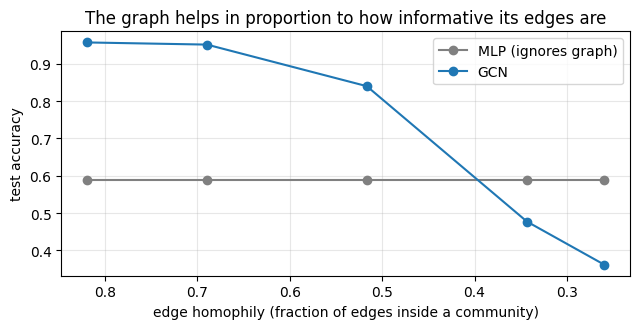

In [8]:
sweep = [0.005, 0.01, 0.02, 0.04, 0.06]
sw = {"MLP (ignores graph)": [], "GCN": []}
hom = []
t0 = time.time()
for p_out in sweep:
    accs = {k: [] for k in sw}; h = []
    for seed in range(2):
        D = make_sbm(200 + seed, p_out=p_out)
        h.append((D["y"][D["ei"][0]] == D["y"][D["ei"][1]]).float().mean().item())
        for name in sw:
            torch.manual_seed(seed)
            accs[name].append(train_node(GNN(layers[name], 16, 32, 4, L=2), D))
    for k in sw: sw[k].append(np.mean(accs[k]))
    hom.append(np.mean(h))
print(f"sweep took {time.time() - t0:.0f} s")
print("p_out   homophily  " + "  ".join(f"{k:>20s}" for k in sw))
for i, p in enumerate(sweep):
    print(f"{p:5.3f}   {hom[i]:.2f}       " + "  ".join(f"{sw[k][i]:20.3f}" for k in sw))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for k, c in zip(sw, ["0.5", "tab:blue"]):
    ax.plot(hom, sw[k], "o-", label=k, color=c)
ax.set_xlabel("edge homophily (fraction of edges inside a community)"); ax.set_ylabel("test accuracy"); ax.legend(); ax.invert_xaxis()
ax.set_title("The graph helps in proportion to how informative its edges are")
plt.tight_layout(); plt.show()

**Reading.** The advantage tracks the homophily of the edges. At homophily 0.82 (few cross-community edges) the GCN reaches 0.96 against 0.59 for the MLP. At 0.52 the GCN still wins (0.84), but at 0.34 it has fallen *below* the MLP (0.48 against 0.59), and at 0.26, where edges carry no information about the community (a node's neighbours look like a random sample of the graph), it drops to 0.36, well under the feature-only model. Message passing with a fixed average is not neutral: when the neighbours disagree with the node it mixes the node's own, weakly informative features with unrelated ones and makes things worse. The MLP line is flat because it never looks at the edges. Two graphs per setting is a small sample, so read the shape of the curve rather than the third decimal. In practice the lesson is to measure homophily before reaching for a GNN, and to use layers that keep the node's own vector separate (GraphSAGE, exercise 2) when the data is heterophilous.

## 6. Depth: over-smoothing and over-squashing

In a CNN, deeper is usually better (module 05 of Neural Networks 1001). In a GNN, going deep is hard, and the reasons are specific to graphs.

**Over-smoothing.** Every layer replaces a node by an average of its neighbourhood. Averaging again and again drives all the nodes of a connected graph towards the *same* vector, and when the nodes look alike no classifier can separate them. Oono and Suzuki (2020) prove that the expressive power of a GCN decays exponentially with depth. We first measure the pure effect of the propagation $\hat A^k X$ (no weights, no training, $k$ steps of the GCN rule): the **mean cosine similarity** between the vectors of all pairs of nodes, which is 0 for unrelated vectors and 1 when they all point the same way. Then we train GCNs of increasing depth and see what happens to accuracy, with and without **residual connections** ($h' = h + \text{layer}(h)$, the trick of module 03 that lets a deep network keep information from earlier layers).

**Over-squashing.** Even before nodes become alike, a deep GNN has a second problem. The receptive field of a node grows exponentially with the number of layers, but all that information must be squeezed through fixed-size vectors along the few paths that connect the distant nodes. Alon and Yahav (2021) call this the bottleneck. We measure it as **sensitivity**: the size of the derivative of a node's output with respect to another node's input features, $\lVert \partial h_t / \partial x_s \rVert$ (norm of the Jacobian, how much a change at source node $s$ moves target node $t$), relative to the sensitivity to its own features, for a randomly initialised GCN. We look at it in two shapes of graph: a **path** (distance matters) and a **star behind a bridge** (many sources share one narrow channel).

k      : [0, 1, 2, 4, 8, 16, 32, 64, 128]
mean cosine similarity: [-0.0, -0.0, -0.0, 0.0, 0.08, 0.94, 1.0, 1.0, 1.0]


depth study took 82 s
GCN              {1: np.float64(0.823), 2: np.float64(0.919), 4: np.float64(0.74), 8: np.float64(0.242), 16: np.float64(0.223)}
GCN + residual   {1: np.float64(0.823), 2: np.float64(0.91), 4: np.float64(0.902), 8: np.float64(0.915), 16: np.float64(0.913)}


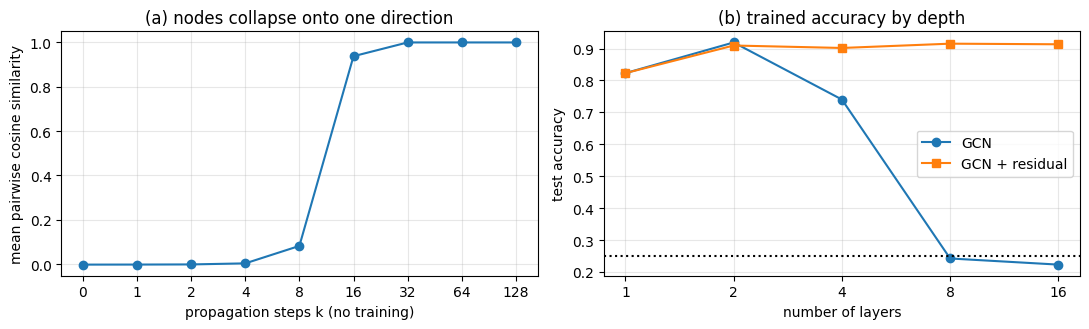

In [9]:
# (a) over-smoothing of pure propagation, no training: mean pairwise cosine similarity of node vectors after k steps of A_hat
D = make_sbm(300)
n_, ei_ = D["n"], D["ei"]
Ah = torch.zeros(n_, n_); Ah[ei_[0], ei_[1]] = 1; Ah += torch.eye(n_)
dv = Ah.sum(1).rsqrt(); Ah = dv[:, None] * Ah * dv[None, :]
def mean_cos(H):
    Hn = F.normalize(H, dim=1); S = Hn @ Hn.T
    return ((S.sum() - n_) / (n_ * (n_ - 1))).item()
H = D["x"] - D["x"].mean(0)                          # centred features, so that similarity 0 means "unrelated"
ks = [0, 1, 2, 4, 8, 16, 32, 64, 128]
cos_k = []
Hk = H.clone(); step = 0
for k in ks:
    while step < k: Hk = Ah @ Hk; step += 1
    cos_k.append(mean_cos(Hk))
print("k      :", ks)
print("mean cosine similarity:", [round(c, 2) for c in cos_k])

# (b) trained GCNs of growing depth, with and without residual connections (2 graphs each)
depths = [1, 2, 4, 8, 16]
dep = {"GCN": [], "GCN + residual": []}
t0 = time.time()
for L in depths:
    a, b = [], []
    for seed in range(2):
        D = make_sbm(400 + seed)
        torch.manual_seed(seed); a.append(train_node(GNN(GCNLayer, 16, 32, 4, L=L, dropout=0.2), D, epochs=80))
        torch.manual_seed(seed); b.append(train_node(GNN(GCNLayer, 16, 32, 4, L=L, dropout=0.2, residual=True), D, epochs=80))
    dep["GCN"].append(np.mean(a)); dep["GCN + residual"].append(np.mean(b))
print(f"depth study took {time.time() - t0:.0f} s")
for k, v in dep.items():
    print(f"{k:16s}", {L: round(x, 3) for L, x in zip(depths, v)})

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(range(len(ks)), cos_k, "o-"); axs[0].set_xticks(range(len(ks))); axs[0].set_xticklabels(ks)
axs[0].set_xlabel("propagation steps k (no training)"); axs[0].set_ylabel("mean pairwise cosine similarity"); axs[0].set_title("(a) nodes collapse onto one direction")
axs[1].plot(range(len(depths)), dep["GCN"], "o-", label="GCN"); axs[1].plot(range(len(depths)), dep["GCN + residual"], "s-", label="GCN + residual")
axs[1].set_xticks(range(len(depths))); axs[1].set_xticklabels(depths); axs[1].axhline(0.25, color="k", ls=":")
axs[1].set_xlabel("number of layers"); axs[1].set_ylabel("test accuracy"); axs[1].legend(); axs[1].set_title("(b) trained accuracy by depth")
plt.tight_layout(); plt.show()

**Reading.** Panel (a): the propagation alone, with no learning, already shows the effect. The mean cosine similarity is about 0 for the raw features and stays near 0 for the first few steps, then rises to 0.08 after 8 steps, 0.94 after 16 and 1.00 from 32 steps on: after enough averaging every node points in the same direction, and the information that distinguished them is gone. Panel (b): the trained GCN is best with 2 layers (0.92) and degrades to 0.74 with 4 and to chance level (0.22 to 0.24) with 8 and 16 layers. We should be honest that this collapse mixes over-smoothing with a plain **optimisation** difficulty (deep stacks without skip connections are hard to train, module 03 of Neural Networks 1001), and our experiment does not separate the two. What it does show is that the residual variant, which has the same layers plus $h' = h + \text{layer}(h)$, stays at 0.90 to 0.92 from 4 to 16 layers: the skip connection lets information from the first layers reach the classifier. It does not beat the 2-layer GCN (0.92 against 0.91 to 0.92), so depth bought nothing on this easy task, and each setting uses only 2 graphs.

path graph, 10 layers: relative influence at distance r = 1..10:
['1.0e+00', '8.4e-01', '5.4e-01', '3.1e-01', '1.6e-01', '7.6e-02', '2.4e-02', '7.2e-03', '1.2e-03', '1.4e-04']


bridge graph, 2 layers: relative influence of one leaf on the target, k leaves behind the bridge:
{1: 0.465, 2: 0.342, 4: 0.266, 8: 0.16, 16: 0.098, 32: 0.056, 64: 0.029}


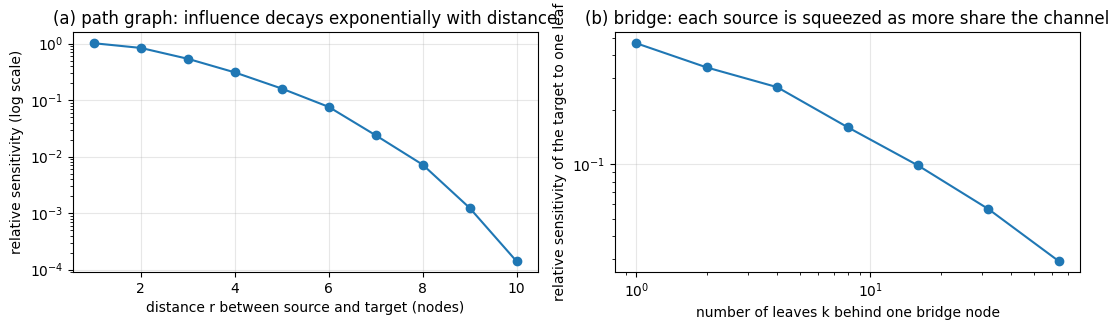

In [10]:
def sensitivity(ei, n, s, t, L, hid=16, seeds=8):
    # |d h_t / d x_s| (Frobenius norm of the Jacobian of node t's output w.r.t. node s's input) divided by the same for t's own input,
    # for a randomly initialised GCN with L layers; the ratio removes the effect of the weight scale.
    vals = []
    for sd in range(seeds):
        torch.manual_seed(sd)
        net = GNN(GCNLayer, 4, hid, hid, L=L, dropout=0.0)
        x = torch.randn(n, 4)
        def f(xx): return net(xx, ei)[t]
        J = torch.autograd.functional.jacobian(f, x)          # (hid, n, 4)
        vals.append((J[:, s].norm() / J[:, t].norm()).item())
    return float(np.mean(vals))

# path graph of 14 nodes, target = node 0, 10 layers: influence of the node at distance r
npath = 14
pe = torch.tensor([[i for i in range(npath - 1)] + [i + 1 for i in range(npath - 1)], [i + 1 for i in range(npath - 1)] + [i for i in range(npath - 1)]])
path_sens = [sensitivity(pe, npath, r, 0, L=10) for r in range(1, 11)]
print("path graph, 10 layers: relative influence at distance r = 1..10:")
print([f"{v:.1e}" for v in path_sens])

# star behind a bridge: target t - bridge b - k leaves; 2 layers; influence of ONE leaf on t
def bridge_graph(k):
    nodes = k + 2; t, b = 0, 1
    edges = [(t, b)] + [(b, 2 + i) for i in range(k)]
    return torch.tensor([[a for a, c in edges] + [c for a, c in edges], [c for a, c in edges] + [a for a, c in edges]]), nodes
ks_leaf = [1, 2, 4, 8, 16, 32, 64]
leaf_sens = []
for k in ks_leaf:
    e, nn_ = bridge_graph(k)
    leaf_sens.append(sensitivity(e, nn_, 2, 0, L=2))
print("bridge graph, 2 layers: relative influence of one leaf on the target, k leaves behind the bridge:")
print({k: round(v, 3) for k, v in zip(ks_leaf, leaf_sens)})

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].semilogy(range(1, 11), path_sens, "o-"); axs[0].set_xlabel("distance r between source and target (nodes)"); axs[0].set_ylabel("relative sensitivity (log scale)")
axs[0].set_title("(a) path graph: influence decays exponentially with distance")
axs[1].loglog(ks_leaf, leaf_sens, "o-"); axs[1].set_xlabel("number of leaves k behind one bridge node"); axs[1].set_ylabel("relative sensitivity of the target to one leaf")
axs[1].set_title("(b) bridge: each source is squeezed as more share the channel")
plt.tight_layout(); plt.show()

**Reading.** Panel (a): on a path, the influence of a node on the target falls from 1.0 at distance 1 to 0.31 at distance 4, 0.024 at distance 7 and 0.00014 at distance 10, roughly an order of magnitude every three hops, even though the network is deep enough to reach all of them. A source 10 hops away has essentially no say. Panel (b): when many sources share one bridge node, the influence of a single leaf shrinks as more leaves are added (0.47 for one leaf, 0.16 for 8, 0.03 for 64), roughly like one over the square root of the number of leaves (a 64-fold increase divides it by about 16), because the fixed-size vector of the bridge has to carry all of them. This is the over-squashing bottleneck, here measured on randomly initialised networks (8 initialisations averaged) to show that it comes from the *structure*, not from training. We did not train a model on a task that needs the far information, so this is a measurement of sensitivity, not of accuracy; Alon and Yahav (2021) give the trained experiments.

**What people do about it** (not measured here): keep the network shallow and widen it instead (2 to 4 layers is the norm), add residual connections or jumping-knowledge connections that read every layer, normalise between layers, **rewire** the graph to add shortcuts across bottlenecks (Topping et al., 2022), or let nodes attend to far-away nodes with a transformer-style layer (graph transformers), which is the GAT-on-a-complete-graph idea of section 4 again.

## 7. Graph-level tasks: molecules and the readout

Now the unit of prediction is a *whole graph*. A drug candidate is a molecular graph (atoms are nodes, bonds are edges) and we want one number for it: is it toxic, how well does it dissolve, does it kill a bacterium? The only new ingredient is the **readout**: after $L$ message-passing layers, collapse the node vectors of each graph into one graph vector with a permutation-invariant function and feed it to an ordinary classifier,

$$h_G = \bigoplus_{i \in V} h_i^{(L)}, \qquad \hat y = \mathrm{MLP}(h_G), \qquad \bigoplus \in \{\text{sum}, \text{mean}, \text{max}\}.$$

**Data.** **MUTAG** has 188 small molecules (about 18 atoms and 20 bonds each) that are nitroaromatic compounds, labelled by whether they have a mutagenic effect on a bacterium (*Salmonella typhimurium*): 125 are mutagenic and 63 are not (Debnath et al., 1991). It is one of the benchmark datasets of the TU Dortmund collection (Morris et al., 2020, https://chrsmrrs.github.io/datasets/); the files are the standard distribution of that collection, published for research use, and the original compounds come from the 1991 paper. We download the 24 kB archive once into `data/` and use the atom type (7 elements) as the one-hot node feature. If there is no network access, the code falls back to generated molecule-like graphs with a planted motif so that the notebook still runs; the printed message says which one is being used.

**Protocol.** 188 graphs is a small set, so we use stratified 5-fold cross-validation (train on 4 fifths, test on the remaining fifth, rotate) and report the mean and standard deviation of the 5 test accuracies. Each model trains for a fixed 100 epochs, so there is no leak from the test fold into the choice of epoch.

**Models.** Feature baseline: logistic regression on the **bag of atoms** (how many atoms of each element, plus the number of atoms). Ignores the graph: the same network with `NoGraphLayer` and a sum readout (a "deep set": each atom is processed alone and then summed). GNNs: GCN with mean, sum and max readouts, GraphSAGE, GAT and GIN. Last, a **structure control**: GCN where we replace each molecule's bonds by the same number of *random* bonds between its atoms, which keeps the atoms and the graph size but destroys the chemistry.

dataset: MUTAG (TU Dortmund collection): 188 graphs, 3371 atoms, 3721 bonds, atoms per graph 17.9 (min 10, max 28), class balance 0.66 positive
atom types (C, N, O, F, I, Cl, Br) total counts: [2395, 345, 593, 12, 1, 23, 2]


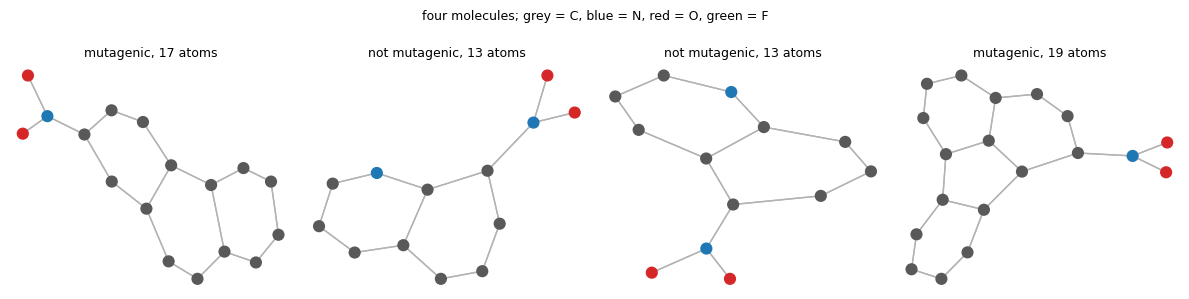

max |output difference| after renumbering the atoms: 1.4901161193847656e-08


In [11]:
CACHE = "data/MUTAG"
URL = "https://www.chrsmrrs.com/graphkerneldatasets/MUTAG.zip"

def load_mutag():
    if not os.path.exists(os.path.join(CACHE, "MUTAG_A.txt")):
        os.makedirs("data", exist_ok=True)
        raw = urllib.request.urlopen(urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"}), timeout=30).read()
        zipfile.ZipFile(io.BytesIO(raw)).extractall("data")
    rd = lambda f: np.loadtxt(os.path.join(CACHE, f"MUTAG_{f}.txt"), delimiter=",", dtype=int)
    A_ = rd("A") - 1; gid = rd("graph_indicator") - 1; nl = rd("node_labels"); gl = rd("graph_labels")
    return A_.T, gid, np.eye(nl.max() + 1)[nl].astype(np.float32), (gl == 1).astype(int)

def fake_molecules(num=188, seed=0):
    # fallback: random tree-like "molecules" over 7 elements; label = contains an N atom bonded to two O atoms (a nitro-like motif)
    g = np.random.RandomState(seed); E, gid, X, y, off = [], [], [], [], 0
    for i in range(num):
        m = g.randint(10, 28); types = g.choice(7, m, p=[.6, .1, .1, .05, .05, .05, .05]); edges = [(j, g.randint(0, j)) for j in range(1, m)]
        if i % 2 == 0:
            a = g.randint(0, m - 2); types[a], types[a + 1], types[(a + 2) % m] = 1, 2, 2; edges += [(a, a + 1), (a, (a + 2) % m)]
        lab = int(any(types[a] == 1 and sum(types[b] == 2 for p, q in edges for b in ([q] if p == a else [p] if q == a else [])) >= 2 for a in range(m)))
        E += [(a + off, b + off) for a, b in edges] + [(b + off, a + off) for a, b in edges]; gid += [i] * m; X += list(np.eye(7)[types]); y.append(lab); off += m
    return np.array(E).T, np.array(gid), np.array(X, dtype=np.float32), np.array(y)

try:
    E_all, gid, X_all, Y = load_mutag(); source = "MUTAG (TU Dortmund collection)"
except Exception as ex:
    print("download failed (", type(ex).__name__, "), using generated molecule-like graphs instead")
    E_all, gid, X_all, Y = fake_molecules(); source = "generated molecule-like graphs"
Ng = len(Y)
sizes = np.bincount(gid)
print(f"dataset: {source}: {Ng} graphs, {X_all.shape[0]} atoms, {E_all.shape[1] // 2} bonds, "
      f"atoms per graph {sizes.mean():.1f} (min {sizes.min()}, max {sizes.max()}), class balance {Y.mean():.2f} positive")
print("atom types (C, N, O, F, I, Cl, Br) total counts:", X_all.sum(0).astype(int).tolist())

def collate(ids, shuffle_edges=None):
    # build one big block-diagonal graph from a subset of graphs
    ids = np.asarray(ids); node_mask = np.isin(gid, ids)
    new_id = -np.ones(len(gid), dtype=int); new_id[node_mask] = np.arange(node_mask.sum())
    remap = {g: i for i, g in enumerate(ids)}
    batch = torch.tensor([remap[g] for g in gid[node_mask]])
    em = node_mask[E_all[0]]; e = new_id[E_all[:, em]]
    if shuffle_edges is not None:
        # control: same number of bonds per molecule, but between random pairs of its atoms
        g_ = np.random.RandomState(shuffle_edges); starts = np.concatenate([[0], np.cumsum(np.bincount(batch.numpy()))])
        cnt = np.bincount(batch.numpy()[e[0]], minlength=len(ids)) // 2; es = []
        for gi in range(len(ids)):
            nn_ = starts[gi + 1] - starts[gi]; a = g_.randint(0, nn_, cnt[gi]); b = (a + g_.randint(1, nn_, cnt[gi])) % nn_
            es += [(starts[gi] + a, starts[gi] + b), (starts[gi] + b, starts[gi] + a)]
        e = np.concatenate([np.array([p[0], p[1]]) for p in es], axis=1)
    return torch.tensor(X_all[node_mask]), torch.tensor(e), batch, torch.tensor(Y[ids]), len(ids)

# draw a few molecules (force layout), colour = element
elem_col = ["0.35", "tab:blue", "tab:red", "tab:green", "tab:purple", "tab:olive", "tab:brown"]
fig, axs = plt.subplots(1, 4, figsize=(12, 3))
for ax, gi in zip(axs, [0, 1, 2, 3]):
    x_, e_, b_, y_, _ = collate([gi]); p_ = layout(e_, x_.shape[0], seed=gi, iters=200)
    for a, b in zip(*e_.numpy()): ax.plot(p_[[a, b], 0], p_[[a, b], 1], color="0.7", lw=1, zorder=1)
    ax.scatter(p_[:, 0], p_[:, 1], c=[elem_col[c] for c in x_.argmax(1).numpy()], s=60, zorder=2)
    ax.set_title(("mutagenic" if y_.item() else "not mutagenic") + f", {x_.shape[0]} atoms", fontsize=9); ax.axis("off")
plt.suptitle("four molecules; grey = C, blue = N, red = O, green = F", fontsize=9); plt.tight_layout(); plt.show()

# the permutation test on a real trained-free network: renumbering the atoms of a molecule does not change the output
x_, e_, b_, y_, ng_ = collate([5])
torch.manual_seed(0); net = GNN(GCNLayer, 7, 32, 2, L=3, readout="sum").eval()
p_ = torch.randperm(x_.shape[0]); inv_ = torch.argsort(p_)
with torch.no_grad():
    o1 = net(x_, e_, b_, ng_); o2 = net(x_[p_], inv_[e_], b_, ng_)
print("max |output difference| after renumbering the atoms:", float((o1 - o2).abs().max()))

5-fold cross-validation of 9 models took 163 s

model                                  accuracy (mean +- std over 5 folds)
Logistic regression (bag of atoms)     0.862 +- 0.038
Ignores graph (deep set, sum)          0.851 +- 0.031
GCN, mean readout                      0.750 +- 0.077
GCN, sum readout                       0.825 +- 0.034
GCN, max readout                       0.771 +- 0.075
GraphSAGE, mean readout                0.739 +- 0.046
GAT, mean readout                      0.761 +- 0.042
GIN, sum readout                       0.846 +- 0.048
GCN sum, RANDOM bonds (control)        0.787 +- 0.070

majority-class rate (always predict 'mutagenic'): 0.665


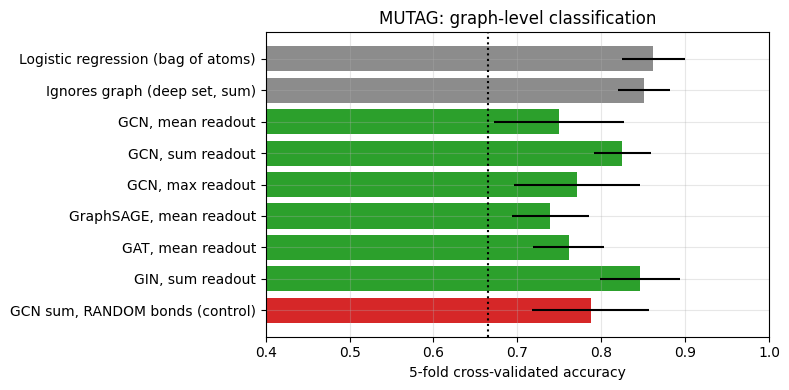

In [12]:
def train_graph(model, train_data, test_data, epochs=100, lr=0.01, wd=1e-4):
    Xt, Et, Bt, Yt, Nt = train_data; Xe, Ee, Be, Ye, Ne = test_data
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        F.cross_entropy(model(Xt, Et, Bt, Nt), Yt).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        return (model(Xe, Ee, Be, Ne).argmax(1) == Ye).float().mean().item()

def bag_of_atoms(ids):
    return np.array([np.append(X_all[gid == g].sum(0), (gid == g).sum()) for g in ids])

configs = {
    "Logistic regression (bag of atoms)": None,
    "Ignores graph (deep set, sum)": (NoGraphLayer, "sum", None),
    "GCN, mean readout": (GCNLayer, "mean", None),
    "GCN, sum readout": (GCNLayer, "sum", None),
    "GCN, max readout": (GCNLayer, "max", None),
    "GraphSAGE, mean readout": (SAGELayer, "mean", None),
    "GAT, mean readout": (GATLayer, "mean", None),
    "GIN, sum readout": (GINLayer, "sum", None),
    "GCN sum, RANDOM bonds (control)": (GCNLayer, "sum", 7),
}
cv_res = {k: [] for k in configs}
skf = StratifiedKFold(5, shuffle=True, random_state=0)
t0 = time.time()
for fold, (tr, te) in enumerate(skf.split(np.zeros(Ng), Y)):
    data = {None: (collate(tr), collate(te)), 7: (collate(tr, 7), collate(te, 7))}      # build each fold's tensors once
    for name, cfg in configs.items():
        if cfg is None:
            clf = LogisticRegression(max_iter=5000, C=1.0).fit(bag_of_atoms(tr), Y[tr])
            cv_res[name].append(clf.score(bag_of_atoms(te), Y[te]))
        else:
            torch.manual_seed(fold)
            m = GNN(cfg[0], 7, 32, 2, L=3, readout=cfg[1], dropout=0.0)
            cv_res[name].append(train_graph(m, *data[cfg[2]]))
print(f"5-fold cross-validation of {len(configs)} models took {time.time() - t0:.0f} s\n")
print(f"{'model':38s} accuracy (mean +- std over 5 folds)")
for k, v in cv_res.items():
    print(f"{k:38s} {np.mean(v):.3f} +- {np.std(v):.3f}")
print(f"\nmajority-class rate (always predict 'mutagenic'): {max(Y.mean(), 1 - Y.mean()):.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
names = list(cv_res); means = [np.mean(v) for v in cv_res.values()]; stds = [np.std(v) for v in cv_res.values()]
cols = ["0.55", "0.55"] + ["tab:green"] * 6 + ["tab:red"]
ax.barh(names[::-1], means[::-1], xerr=stds[::-1], color=cols[::-1])
ax.axvline(max(Y.mean(), 1 - Y.mean()), color="k", ls=":"); ax.set_xlim(0.4, 1.0)
ax.set_xlabel("5-fold cross-validated accuracy"); ax.set_title("MUTAG: graph-level classification")
plt.tight_layout(); plt.show()

**Reading.** Here the honest result is **negative for the graph**. The simplest model, logistic regression on the count of each element, scores 0.86, and the deep set that processes every atom alone and sums them scores 0.85. No GNN beats them: GIN with a sum readout is the closest (0.85), GCN with a sum readout gets 0.83, and the mean-readout models (GCN 0.75, GraphSAGE 0.74, GAT 0.76) and the max readout (0.77) are clearly lower. With 188 molecules and 5 folds the fold-to-fold standard deviations are 0.03 to 0.08, so differences below about 0.04 (baseline versus GIN, GCN-sum versus the baseline) cannot be told apart from noise, while the 0.1 gap to the mean-readout models is probably real. Two lessons follow. First, the readout matters: the **sum** keeps the *number* of nitrogen and oxygen atoms (mutagenicity of these nitro compounds is tied to such groups), which a mean throws away; this is the argument of Xu et al. (2019) for sum-based layers. Second, the random-bonds control (0.79) is about as good as the true-bond GCN with the same readout (0.83) given the noise, which says that on this small dataset with a 100-epoch budget the networks mostly use *which atoms are present* and not *how they are bonded*. That does not mean chemistry structure is irrelevant in general: published results on MUTAG with tuned models and edge (bond type) features are higher and the dataset is known to be small and nearly saturated by simple descriptors. We fixed the training budget, did not tune any hyperparameter, and used one fold split, so treat the ranking of the GNN variants as provisional (exercise 6).

**Where the toy differs from real systems.** Our graphs have hundreds of nodes or about 18 atoms, the layers are full-batch on a CPU, and the bond *types* (single, double, aromatic) and 3D geometry of the molecules are ignored. Production drug-discovery models use millions of molecules, edge features, 3D coordinates and many layers of message passing with GPUs, and web-scale recommenders sample neighbourhoods (the GraphSAGE idea) because the graph does not fit in memory.

## 8. Where GNNs are used in production

The same layer, applied to very different graphs. In all of these the data has a natural graph that a plain MLP or CNN cannot respect.

| Domain | The graph | What the GNN does | Reference |
|---|---|---|---|
| **Weather** | the Earth's surface as a mesh of about a million grid points, edges between nearby points | **GraphCast** predicts the global state of the atmosphere 10 days ahead in under a minute, and beat the leading operational numerical forecast on most verification targets | Lam et al. (2023), Science |
| **Traffic and routing** | road segments as nodes, connected where they meet | the estimated time of arrival in Google Maps comes from a GNN over "supersegments" of the road network, with large reductions of bad estimates in several cities | Derrow-Pinion et al. (2021) |
| **Drug discovery** | atoms and bonds of a molecule | a message-passing network on molecules found halicin, a new antibiotic that was then confirmed in the laboratory | Stokes et al. (2020), Cell |
| **Power grids** | buses (substations) as nodes, transmission lines as edges | a GNN learns to solve the power-flow equations as a fast surrogate for the iterative solver | Donon et al. (2020) |
| **Recommendation** | users and items, linked by clicks and saves | PinSage, a GraphSAGE-style network sampled over a graph of 3 billion nodes, powers related-pins recommendations at Pinterest | Ying et al. (2018) |

The other places to look: GNN layers inside protein-structure and molecular-dynamics models, fraud detection on transaction graphs, particle-physics event reconstruction, chip design and knowledge graphs. A recurring pattern is that the GNN is a *learned fast approximation* of something slow (a numerical simulation, a physics solver, a lab experiment) or a way to bring relational structure into a recommender. Module 09 of this course looks at the first idea (scientific machine learning) in more detail.

## 9. Key takeaways, exercises, references

## Key takeaways

* A graph has no grid and no order, so a model must be **permutation equivariant** (per-node outputs) or **invariant** (one output per graph). Aggregating neighbours with a sum, mean or maximum gives that for free, and we verified it numerically.
* **Message passing** (message, aggregate, update) is one template. GCN uses a fixed degree-normalised average, GraphSAGE separates a node from its neighbours, GAT learns the neighbour weights with attention, and GIN uses a sum. A GAT with an all-ones mask is the transformer attention of module 09 of Neural Networks 1001.
* On a network with known communities the graph is worth as much as the **homophily** of its edges: see the measured numbers in section 5. When edges carry no signal, a GNN has no advantage and can lose to a model that ignores the graph.
* Depth is limited by **over-smoothing** (nodes become alike) and **over-squashing** (too much information through too narrow a channel). We measured both. Shallow networks, residual connections and rewiring are the usual remedies.
* For graph-level tasks a **readout** pools the nodes. The choice (sum, mean, max) matters, and on a small dataset like MUTAG differences of a few points are within the cross-validation noise.
* Always compare against a model that ignores the graph and against a plain feature baseline. If the GNN does not beat them, the graph is not adding information.

## Exercises

1. In section 5, change `signal` from 0.4 to 0.1 and to 1.0. How do the MLP and the GCN respond? Where does the gap between them close?
2. Add a **heterophilous** setting: let nodes link *across* communities more than inside (for example $p_{\text{in}} = 0.01$ and $p_{\text{out}} = 0.05$). Which model degrades most, and does GraphSAGE (which keeps the node's own vector separate) hold up better than GCN?
3. Plot the attention weights `last_alpha` of the first `GATLayer` for one node of the SBM, split by whether the neighbour is in the same community. Does the GAT learn to listen more to same-community neighbours?
4. In section 6, repeat the depth study with GraphSAGE and with GAT. Do they over-smooth as fast as GCN? Try 16 layers with dropout 0 and weight decay 0.
5. In section 7 add the **bond type** (the `MUTAG_edge_labels.txt` file) as an edge feature: multiply each message by a learned embedding of the bond type. Does the accuracy move beyond the fold noise?
6. Repeat the MUTAG cross-validation with 5 different fold shuffles (`random_state`) and look at the spread of the means. Which of the differences you saw in the table survive?
7. Replace the mean readout by an attention readout: a learned score per node, a softmax over the nodes of each graph, a weighted sum. Compare.
8. Implement neighbour **sampling** for GraphSAGE: keep at most 5 random incoming edges per node at each training step, and test with all of them. How much accuracy do you lose, and how much faster is a step on the 2000-node, 20000-edge random graph of section 3?

## References

* Gilmer, J., Schoenholz, S. S., Riley, P. F., Vinyals, O. and Dahl, G. E. (2017). Neural message passing for quantum chemistry. ICML 2017. arXiv:1704.01212: https://arxiv.org/abs/1704.01212
* Kipf, T. N. and Welling, M. (2017). Semi-supervised classification with graph convolutional networks. ICLR 2017. arXiv:1609.02907: https://arxiv.org/abs/1609.02907
* Hamilton, W. L., Ying, R. and Leskovec, J. (2017). Inductive representation learning on large graphs (GraphSAGE). NeurIPS 2017. arXiv:1706.02216: https://arxiv.org/abs/1706.02216
* Velickovic, P., Cucurull, G., Casanova, A., Romero, A., Lio, P. and Bengio, Y. (2018). Graph attention networks. ICLR 2018. arXiv:1710.10903: https://arxiv.org/abs/1710.10903
* Xu, K., Hu, W., Leskovec, J. and Jegelka, S. (2019). How powerful are graph neural networks? (GIN). ICLR 2019. arXiv:1810.00826: https://arxiv.org/abs/1810.00826
* Bronstein, M. M., Bruna, J., Cohen, T. and Velickovic, P. (2021). Geometric deep learning: grids, groups, graphs, geodesics, and gauges. arXiv:2104.13478: https://arxiv.org/abs/2104.13478
* Oono, K. and Suzuki, T. (2020). Graph neural networks exponentially lose expressive power for node classification. ICLR 2020. arXiv:1905.10947: https://arxiv.org/abs/1905.10947
* Alon, U. and Yahav, E. (2021). On the bottleneck of graph neural networks and its practical implications. ICLR 2021. arXiv:2006.05205: https://arxiv.org/abs/2006.05205
* Topping, J., Di Giovanni, F., Chamberlain, B. P., Dong, X. and Bronstein, M. M. (2022). Understanding over-squashing and bottlenecks on graphs via curvature. ICLR 2022. arXiv:2111.14522: https://arxiv.org/abs/2111.14522
* Morris, C., Kriege, N. M., Bause, F., Kersting, K., Mutzel, P. and Neumann, M. (2020). TUDataset: a collection of benchmark datasets for learning with graphs. arXiv:2007.08663: https://arxiv.org/abs/2007.08663 (data: https://chrsmrrs.github.io/datasets/)
* Debnath, A. K., Lopez de Compadre, R. L., Debnath, G., Shusterman, A. J. and Hansch, C. (1991). Structure-activity relationship of mutagenic aromatic and heteroaromatic nitro compounds (MUTAG). *Journal of Medicinal Chemistry* 34(2), 786-797: https://doi.org/10.1021/jm00106a046
* Lam, R. et al. (2023). Learning skillful medium-range global weather forecasting (GraphCast). *Science* 382(6677), 1416-1421: https://doi.org/10.1126/science.adi2336
* Derrow-Pinion, A. et al. (2021). ETA prediction with graph neural networks in Google Maps. CIKM 2021. arXiv:2108.11482: https://arxiv.org/abs/2108.11482
* Stokes, J. M. et al. (2020). A deep learning approach to antibiotic discovery. *Cell* 180(4), 688-702: https://doi.org/10.1016/j.cell.2020.01.021
* Donon, B., Clément, R., Donnot, B., Marot, A., Guyon, I. and Schoenauer, M. (2020). Neural networks for power flow: graph neural solver. *Electric Power Systems Research* 189, 106547: https://doi.org/10.1016/j.epsr.2020.106547
* Ying, R., He, R., Chen, K., Eksombatchai, P., Hamilton, W. L. and Leskovec, J. (2018). Graph convolutional neural networks for web-scale recommender systems (PinSage). KDD 2018. arXiv:1806.01973: https://arxiv.org/abs/1806.01973

In [13]:
print(f"total notebook run time: {time.time() - T_START:.0f} s")

total notebook run time: 352 s
